In [41]:
!pip install pandas 
!pip install numpy 
!pip install matplotlib 
!pip install RDkit 
!pip install scikit-learn
!pip install lightgbm


[notice] A new release of pip is available: 24.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 24.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 24.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 24.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 24.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ---------------------------------------- 1.4/1.4 MB 27.0 MB/s eta 0:00:00



[notice] A new release of pip is available: 24.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [36]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import rdkit
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import cross_val_score, train_test_split, KFold, cross_val_score, RandomizedSearchCV

# Read the molecules' Extended Connectivity FINGERPRINTS dataset, which contains the structure information

In [15]:
# replace the first line with the number 0 and 1 and let them be the column names
df_fingerprints=pd.read_csv("SMRT_ECFP_1024_Fingerprints.txt", skiprows=1, sep='\t',dtype=str, header=None)
# Abstract the first column as pubchem_ids and convert them to integers

df_fingerprints=df_fingerprints.rename(columns={0: 'pubchem',1: 'fingerprints'})
# Abstract the second column as fingerprints and convert them to a numpy array of integers

print(df_fingerprints[:5])

  pubchem                                       fingerprints
0    5139  0100000000010000000000000000000000001000000000...
1    3505  0000010000000100100000010000000000000000000010...
2    2159  1000000000000100100000000000000000000000000000...
3    1340  1000000100000000100000100000000000000000000000...
4    3344  0000000000000100101000000000000000000001000000...


# Load the retention time data 

In [16]:
df_rt=pd.read_csv("SMRT_dataset.csv", sep=';')
print(df_rt[:5])
print(df_rt.shape)

   pubchem     rt                                              inchi
0     5139   93.5    InChI=1S/C3H8N2S/c1-2-6-3(4)5/h2H2,1H3,(H3,4,5)
1     3505  687.8  InChI=1S/C19H25Cl2N3O3/c1-27-19(26)23-8-9-24(1...
2     2159  590.7  InChI=1S/C17H27N3O4S/c1-4-20-8-6-7-12(20)11-19...
3     1340  583.6  InChI=1S/C9H7NO2/c11-8-3-1-2-7-6(8)4-5-10-9(7)...
4     3344  579.0  InChI=1S/C15H20N2O2/c18-14-16-12-15(19-14)7-10...
(80038, 3)


# Merge the retention time dataset with the fingerprints dataset

In [22]:
df_fingerprints['pubchem'] = df_fingerprints['pubchem'].astype(int)
df_rt['pubchem'] = df_rt['pubchem'].astype(int)
df_combined=pd.merge(df_fingerprints, df_rt, on='pubchem', how='inner')


print(df_combined[:5])

   pubchem                                       fingerprints     rt  \
0     5139  0100000000010000000000000000000000001000000000...   93.5   
1     3505  0000010000000100100000010000000000000000000010...  687.8   
2     2159  1000000000000100100000000000000000000000000000...  590.7   
3     1340  1000000100000000100000100000000000000000000000...  583.6   
4     3344  0000000000000100101000000000000000000001000000...  579.0   

                                               inchi  
0    InChI=1S/C3H8N2S/c1-2-6-3(4)5/h2H2,1H3,(H3,4,5)  
1  InChI=1S/C19H25Cl2N3O3/c1-27-19(26)23-8-9-24(1...  
2  InChI=1S/C17H27N3O4S/c1-4-20-8-6-7-12(20)11-19...  
3  InChI=1S/C9H7NO2/c11-8-3-1-2-7-6(8)4-5-10-9(7)...  
4  InChI=1S/C15H20N2O2/c18-14-16-12-15(19-14)7-10...  


# Split the dataset into training, validating and testing dataset 

In [ ]:
y = df_combined['rt'] # Get the target feature
X = np.array(
    [
        [int(bit) for bit in str(fp_str).strip()]
        for fp_str in df_combined['fingerprints']
    ]
) # Get the features as a numpy array

X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42, test_size=0.2)
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, random_state=42, test_size=0.2, )

X_train

array([[0, 1, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [1, 0, 0, ..., 0, 0, 0],
       [1, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]], shape=(5, 1024))

# Train a Random Foreset regressor

We use regression tree to analyse the SMRT dataset. We use RandomForestRegressor to fit a regression tree in order to predict retention time.

In [31]:
reg_class = RandomForestRegressor(random_state=42)

reg_class.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease o

In [32]:
pred_train = reg_class.predict(X_train)
pred_val = reg_class.predict(X_val)
pred_test = reg_class.predict(X_test)

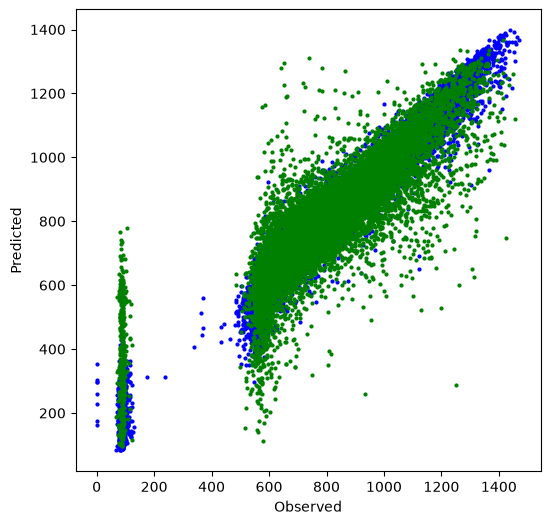

In [33]:
fig, ax = plt.subplots(figsize=(6,6))

ax.scatter(y_train, pred_train, c='blue', s=4)
ax.scatter(y_test, pred_test, c='green', s=4)
ax.set_xlabel('Observed')
ax.set_ylabel('Predicted')
#ax.set_xlim(0, 18)
#ax.set_ylim(0, 18)
plt.show()

In [34]:
score_reg_train = reg_class.score(X_train, y_train)
score_reg_test = reg_class.score(X_test, y_test)
print('Accuracy of RandomForestRegressor on train data: {:.4f}'.format(score_reg_train))
print('Accuracy of RandomForestRegressor on test data: {:.4f}'.format(score_reg_test))
#scores_reg_val = cross_val_score(reg_class, X_reg_train, y_reg_train, cv=KFold())
#print("Accuracy RandomForestRegressor on cross validation: %0.4f ( %0.2f)" % (scores_reg_val.mean(), scores_reg_val.std()))

Accuracy of RandomForestRegressor on train data: 0.9648
Accuracy of RandomForestRegressor on test data: 0.7453


# Solve the overfitting problem

In [35]:
reg_class = RandomForestRegressor(n_estimators=100,
    max_depth=20,  # 限制树深提速
    n_jobs=-1,  # 🌟 模型内部开启全核并行
    random_state=42)
scores_reg_val = cross_val_score(reg_class, X_train, y_train, cv=5, n_jobs=-1)
print("Accuracy RandomForestRegressor on cross validation: %0.4f ( %0.2f)" % (scores_reg_val.mean(), scores_reg_val.std()))

Accuracy RandomForestRegressor on cross validation: 0.7245 ( 0.01)


In [37]:
reg_class.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",20
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max

In [38]:
score_reg_train = reg_class.score(X_train, y_train)
score_reg_test = reg_class.score(X_test, y_test)
print('Accuracy of RandomForestRegressor on train data: {:.4f}'.format(score_reg_train))
print('Accuracy of RandomForestRegressor on test data: {:.4f}'.format(score_reg_test))

Accuracy of RandomForestRegressor on train data: 0.9178
Accuracy of RandomForestRegressor on test data: 0.7262


In [40]:


# 1. 定义候选参数网格
param_dist = {
    'max_depth': [20, 25, 30,50,100],
    'min_samples_leaf': [2, 5, 10],
    'min_samples_split': [5, 10, 20],
   
}

# 2. 初始化基础模型（开启 n_jobs=-1 全核加速）
rf = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)

# 3. 随机搜索最佳参数组合（在训练集 X_train 上做 3 折交叉验证）
random_search = RandomizedSearchCV(
    estimator=rf,
    param_distributions=param_dist,
    n_iter=10,  # 随机尝试 10 组组合
    cv=3,
    scoring='r2',
    random_state=42,
    n_jobs=-1,
)

random_search.fit(X_train, y_train)

# 4. 获取调参后的最佳模型
best_rf = random_search.best_estimator_
print('最佳超参数:', random_search.best_params_)

# 5. 用最佳模型重新评估测试集
best_train_score = best_rf.score(X_train, y_train)
best_test_score = best_rf.score(X_test, y_test)

print(f'调参后训练集 R^2: {best_train_score:.4f}')
print(f'调参后测试集 R^2: {best_test_score:.4f}')

最佳超参数: {'min_samples_split': 5, 'min_samples_leaf': 5, 'max_depth': 100}
调参后训练集 R^2: 0.8763
调参后测试集 R^2: 0.7346


In [42]:
import lightgbm as lgb

# 1. 初始化 LightGBM 回归模型
lgb_model = lgb.LGBMRegressor(
    n_estimators=300,
    learning_rate=0.05,
    num_leaves=63,  # 控制模型复杂度
    subsample=0.8,
    colsample_bytree=0.8,  # 特征随机采样
    random_state=42,
    n_jobs=-1,
)

# 2. 训练与评估
lgb_model.fit(X_train, y_train)

print(f'LightGBM 训练集 R^2: {lgb_model.score(X_train, y_train):.4f}')
print(f'LightGBM 测试集 R^2: {lgb_model.score(X_test, y_test):.4f}')

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.062809 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2048
[LightGBM] [Info] Number of data points in the train set: 51224, number of used features: 1024
[LightGBM] [Info] Start training from score 789.548540
LightGBM 训练集 R^2: 0.8484
LightGBM 测试集 R^2: 0.7834


In [43]:
import lightgbm as lgb

lgb_model = lgb.LGBMRegressor(
    n_estimators=600,  # 增加迭代轮数
    learning_rate=0.03,  # 降低学习率，让拟合更细腻
    num_leaves=127,  # 增加树的叶子节点数（从默认 31 升到 127），增强指纹子结构捕捉能力
    subsample=0.8,
    colsample_bytree=0.7,  # 特征随机采样，防止过拟合
    random_state=42,
    n_jobs=-1,
)

lgb_model.fit(X_train, y_train)

print(f'微调后 LightGBM 训练集 R^2: {lgb_model.score(X_train, y_train):.4f}')
print(f'微调后 LightGBM 测试集 R^2: {lgb_model.score(X_test, y_test):.4f}')

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.063379 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2048
[LightGBM] [Info] Number of data points in the train set: 51224, number of used features: 1024
[LightGBM] [Info] Start training from score 789.548540
微调后 LightGBM 训练集 R^2: 0.9078
微调后 LightGBM 测试集 R^2: 0.8054


X_fp = np.array([[int(bit) for bit in fp_str.strip()] for fp_str in df_raw[1]])